In [15]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text processing
import re

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Save model
import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [16]:
# Download IMDb training and testing CSV files
train_url = "https://huggingface.co/datasets/stanfordnlp/imdb/resolve/main/plain_text/train-00000-of-00001.parquet"
test_url = "https://huggingface.co/datasets/stanfordnlp/imdb/resolve/main/plain_text/test-00000-of-00001.parquet"

train_df = pd.read_parquet(train_url)
test_df = pd.read_parquet(test_url)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

display(train_df.head())

Training shape: (25000, 2)
Testing shape: (25000, 2)


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [17]:
# Check dataset information
print("Training dataset information:")
train_df.info()

# Check missing values
print("\nMissing values:")
print(train_df.isnull().sum())

# Check duplicate reviews
print("\nDuplicate reviews:", train_df.duplicated().sum())

# Check target labels
print("\nLabel distribution:")
print(train_df["label"].value_counts())

Training dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB

Missing values:
text     0
label    0
dtype: int64

Duplicate reviews: 96

Label distribution:
label
0    12500
1    12500
Name: count, dtype: int64


Negative reviews (0): 12500
Positive reviews (1): 12500


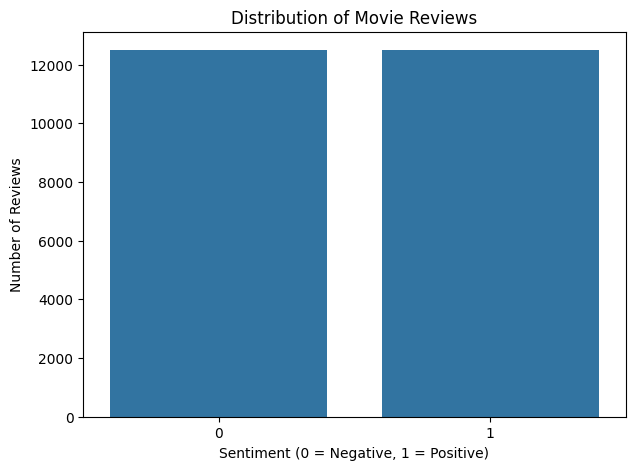

In [18]:
# Count positive and negative reviews
sentiment_counts = train_df["label"].value_counts().sort_index()

print("Negative reviews (0):", sentiment_counts[0])
print("Positive reviews (1):", sentiment_counts[1])

# Visualize sentiment distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=train_df, x="label")

plt.title("Distribution of Movie Reviews")
plt.xlabel("Sentiment (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Reviews")

plt.show()

In [19]:
# Display one negative review
print("NEGATIVE REVIEW:")
print(train_df[train_df["label"] == 0]["text"].iloc[0])

print("\n" + "=" * 80 + "\n")

# Display one positive review
print("POSITIVE REVIEW:")
print(train_df[train_df["label"] == 1]["text"].iloc[0])

NEGATIVE REVIEW:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and

Average review length:
label
0    230.86784
1    236.70656
Name: word_count, dtype: float64


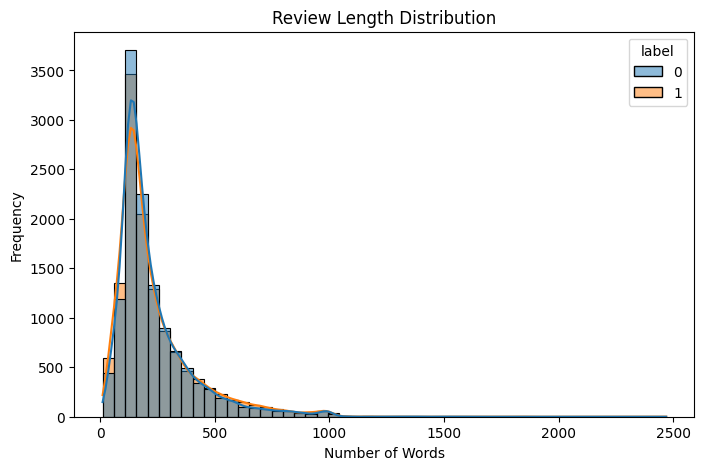

In [20]:
# Calculate the number of words in each review
train_df["word_count"] = train_df["text"].apply(
    lambda review: len(review.split())
)

# Average review length for each sentiment
print("Average review length:")
print(train_df.groupby("label")["word_count"].mean())

# Visualize review lengths
plt.figure(figsize=(8, 5))

sns.histplot(
    data=train_df,
    x="word_count",
    hue="label",
    bins=50,
    kde=True
)

plt.title("Review Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [21]:
import re

def clean_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [22]:
# Clean training and testing reviews
train_df["clean_text"] = train_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)

# Compare original and cleaned reviews
print("ORIGINAL REVIEW:")
print(train_df["text"].iloc[0][:500])

print("\nCLEANED REVIEW:")
print(train_df["clean_text"].iloc[0][:500])

ORIGINAL REVIEW:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent

CLEANED REVIEW:
i rented i am curious yellow from my video store because of all the controversy that surrounded it when it was first released in i also heard that at first it was seized by u s customs if it ever tried to enter this country therefore being a fan of films considered controversial i really had to see this for myself the plot is centered around a young swedish drama student named lena who wants to learn everything she can about life in particular she wants to focu

In [23]:
# Check for empty reviews after cleaning
print("Empty training reviews:", (train_df["clean_text"] == "").sum())
print("Empty testing reviews:", (test_df["clean_text"] == "").sum())

# Display cleaned samples
display(train_df[["text", "clean_text", "label"]].head())

Empty training reviews: 0
Empty testing reviews: 0


,text,clean_text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,i rented i am curious yellow from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",i am curious yellow is a risible and pretentio...,0
2,If only to avoid making this type of film in t...,if only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,this film was probably inspired by godard s ma...,0
4,"Oh, brother...after hearing about this ridicul...",oh brother after hearing about this ridiculous...,0


In [24]:
# Convert text into numerical features using TF-IDF
tfidf_vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

print("TF-IDF vectorizer created!")

TF-IDF vectorizer created!


In [25]:
# Fit TF-IDF on training reviews
X_train = tfidf_vectorizer.fit_transform(train_df["clean_text"])

# Transform testing reviews using the same vectorizer
X_test = tfidf_vectorizer.transform(test_df["clean_text"])

# Extract target labels
y_train = train_df["label"]
y_test = test_df["label"]

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training feature shape: (25000, 10000)
Testing feature shape: (25000, 10000)
Training labels shape: (25000,)
Testing labels shape: (25000,)


In [26]:
# Get feature names
feature_names = tfidf_vectorizer.get_feature_names_out()

# Display first 20 features
print("First 20 TF-IDF features:")
print(feature_names[:20])

# Display numerical representation of first review
print("\nFirst review numerical representation:")
print(X_train[0].toarray())

First 20 TF-IDF features:
['abandoned' 'abc' 'abilities' 'ability' 'ability to' 'able' 'able to'
 'about' 'about all' 'about an' 'about and' 'about any' 'about as'
 'about her' 'about him' 'about his' 'about how' 'about it'
 'about minutes' 'about that']

First review numerical representation:
[[0. 0. 0. ... 0. 0. 0.]]


In [27]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [28]:
# Import Multinomial Naive Bayes
from sklearn.naive_bayes import MultinomialNB

# Create the model
naive_bayes_model = MultinomialNB()

# Train the model
naive_bayes_model.fit(X_train, y_train)

print("Multinomial Naive Bayes training completed!")

Multinomial Naive Bayes training completed!


In [29]:
# Logistic Regression predictions
logistic_predictions = logistic_model.predict(X_test)

# Naive Bayes predictions
naive_bayes_predictions = naive_bayes_model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Logistic Regression predictions:")
print(logistic_predictions[:10])

print("\nFirst 10 Naive Bayes predictions:")
print(naive_bayes_predictions[:10])

Predictions generated successfully!

First 10 actual labels:
[0 0 0 0 0 0 0 0 0 0]

First 10 Logistic Regression predictions:
[0 0 0 0 1 0 0 0 0 0]

First 10 Naive Bayes predictions:
[0 0 0 0 1 0 0 0 0 0]


In [30]:
def evaluate_model(model_name, actual, predicted):
    print("\n" + "=" * 50)
    print(model_name)
    print("=" * 50)

    print("Accuracy:", round(accuracy_score(actual, predicted), 4))
    print("Precision:", round(precision_score(actual, predicted), 4))
    print("Recall:", round(recall_score(actual, predicted), 4))
    print("F1 Score:", round(f1_score(actual, predicted), 4))

    print("\nClassification Report:")
    print(classification_report(
        actual,
        predicted,
        target_names=["Negative", "Positive"]
    ))

In [31]:
evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_predictions
)


Logistic Regression
Accuracy: 0.8943
Precision: 0.8908
Recall: 0.8989
F1 Score: 0.8948

Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.89      0.89     12500
    Positive       0.89      0.90      0.89     12500

    accuracy                           0.89     25000
   macro avg       0.89      0.89      0.89     25000
weighted avg       0.89      0.89      0.89     25000



In [32]:
evaluate_model(
    "Multinomial Naive Bayes",
    y_test,
    naive_bayes_predictions
)


Multinomial Naive Bayes
Accuracy: 0.8618
Precision: 0.861
Recall: 0.8629
F1 Score: 0.8619

Classification Report:
              precision    recall  f1-score   support

    Negative       0.86      0.86      0.86     12500
    Positive       0.86      0.86      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000



In [33]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Multinomial Naive Bayes"],
    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, naive_bayes_predictions)
    ],
    "Precision": [
        precision_score(y_test, logistic_predictions),
        precision_score(y_test, naive_bayes_predictions)
    ],
    "Recall": [
        recall_score(y_test, logistic_predictions),
        recall_score(y_test, naive_bayes_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, logistic_predictions),
        f1_score(y_test, naive_bayes_predictions)
    ]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8943,0.8908,0.8989,0.8948
1,Multinomial Naive Bayes,0.8618,0.8610,0.8629,0.8619


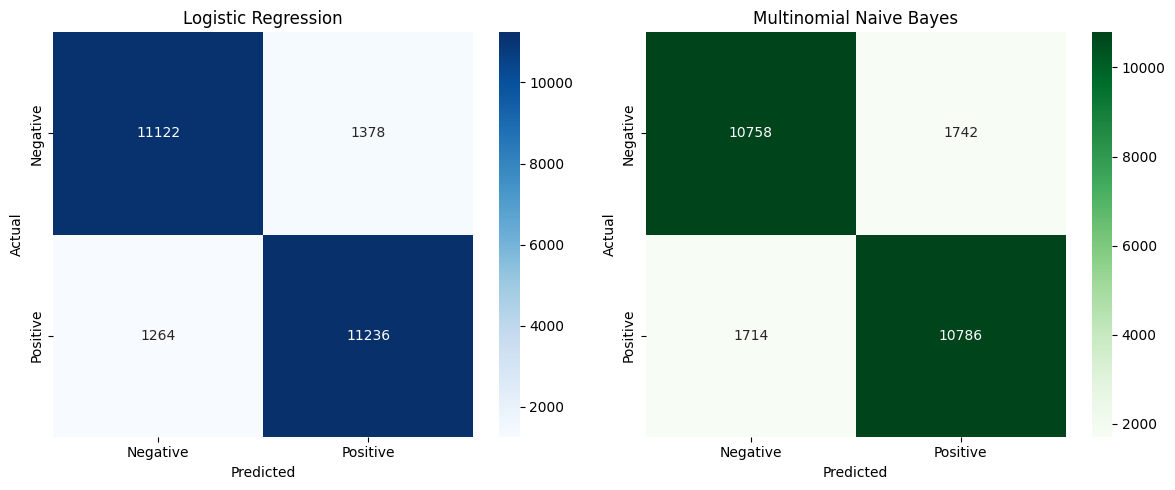

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
sns.heatmap(
    confusion_matrix(y_test, logistic_predictions),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Naive Bayes
sns.heatmap(
    confusion_matrix(y_test, naive_bayes_predictions),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
    ax=axes[1]
)

axes[1].set_title("Multinomial Naive Bayes")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

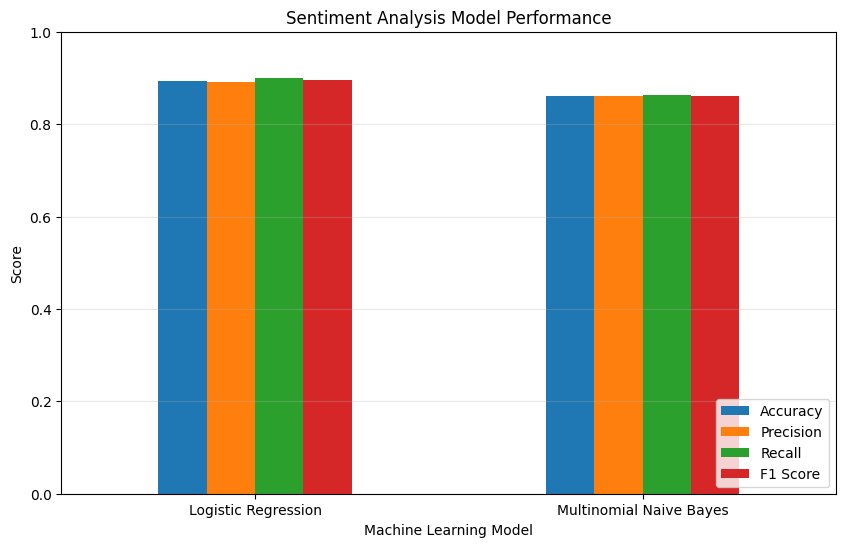

In [35]:
# Convert model results into a format suitable for plotting
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_plot = results.set_index("Model")[metrics]

# Create comparison chart
results_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Sentiment Analysis Model Performance")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [36]:
# Identify the model with the highest F1 score
best_model_name = results.loc[
    results["F1 Score"].idxmax(), "Model"
]

print("Best model based on F1 Score:", best_model_name)

Best model based on F1 Score: Logistic Regression


In [37]:
def predict_sentiment(review, model):
    # Clean the input review
    cleaned_review = clean_text(review)

    # Convert review into TF-IDF features
    review_features = tfidf_vectorizer.transform([cleaned_review])

    # Predict sentiment
    prediction = model.predict(review_features)[0]

    if prediction == 1:
        return "Positive"
    else:
        return "Negative"

In [38]:
sample_reviews = [
    "This movie was absolutely amazing. I loved every moment!",
    "The movie was terrible and boring. I hated it.",
    "The acting was brilliant and the story was wonderful.",
    "Waste of time. Very disappointing movie."
]

for review in sample_reviews:
    prediction = predict_sentiment(review, logistic_model)

    print("Review:", review)
    print("Predicted Sentiment:", prediction)
    print("-" * 70)

Review: This movie was absolutely amazing. I loved every moment!
Predicted Sentiment: Positive
----------------------------------------------------------------------
Review: The movie was terrible and boring. I hated it.
Predicted Sentiment: Negative
----------------------------------------------------------------------
Review: The acting was brilliant and the story was wonderful.
Predicted Sentiment: Positive
----------------------------------------------------------------------
Review: Waste of time. Very disappointing movie.
Predicted Sentiment: Negative
----------------------------------------------------------------------


In [39]:
import joblib

# Select the best model based on F1 score
if best_model_name == "Logistic Regression":
    best_model = logistic_model
else:
    best_model = naive_bayes_model

# Save model and TF-IDF vectorizer together
model_artifact = {
    "vectorizer": tfidf_vectorizer,
    "model": best_model,
    "model_name": best_model_name
}

joblib.dump(model_artifact, "sentiment_analysis_model.pkl")

print("Best model:", best_model_name)
print("Model saved successfully!")

Best model: Logistic Regression
Model saved successfully!


In [40]:
# Load the saved model artifact
loaded_artifact = joblib.load("sentiment_analysis_model.pkl")

loaded_vectorizer = loaded_artifact["vectorizer"]
loaded_model = loaded_artifact["model"]

print("Loaded model:", loaded_artifact["model_name"])
print("Model loaded successfully!")

Loaded model: Logistic Regression
Model loaded successfully!


In [41]:
def predict_new_review(review):
    # Clean the review
    cleaned_review = clean_text(review)

    # Convert text using saved TF-IDF vectorizer
    review_vector = loaded_vectorizer.transform([cleaned_review])

    # Predict sentiment
    prediction = loaded_model.predict(review_vector)[0]

    # Get prediction probability
    probability = loaded_model.predict_proba(review_vector)[0]

    sentiment = "Positive" if prediction == 1 else "Negative"
    confidence = probability[prediction] * 100

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("Model Probability for Predicted Class:", round(confidence, 2), "%")


predict_new_review("This movie was fantastic, emotional and beautifully directed!")

Review: This movie was fantastic, emotional and beautifully directed!
Predicted Sentiment: Positive
Model Probability for Predicted Class: 86.4 %


In [42]:
from google.colab import files

# Download the saved sentiment analysis model
files.download("sentiment_analysis_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>